# Multi-Modality Species Detection Heatmaps

This notebook generates detection heatmaps for three different data modalities:
1. **Drone Videos** - Frame-by-frame animal detection from aerial footage (Père David's Deer)
2. **Bioacoustic Data** - Audio recordings with bird species identification
3. **Camera Trap Photos** - Static image-based wildlife detection

Each heatmap visualizes detection patterns across time dimensions.

In [ ]:
# Required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import glob
import os
import warnings
warnings.filterwarnings('ignore')

# Set style for publication-quality plots
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 12

## 1. Load and Explore Data

In [ ]:
# Load drone telemetry data
drone_df = pd.read_csv('20250703_parrotanafi_1_telemetry_data.csv')
print("DRONE VIDEO DATA")
print(f"Shape: {drone_df.shape}")
print(f"\nColumns: {drone_df.columns.tolist()}")
print(f"\nDate range: {drone_df['date_time'].min()} to {drone_df['date_time'].max()}")
print(f"\nTotal animals detected: {drone_df['num_animals'].sum()}")
print(f"Frames with detections: {(drone_df['num_animals'] > 0).sum()}")
drone_df.head()

DRONE VIDEO DATA
Shape: (1637, 7)

Columns: ['filename', 'num_animals', 'latitude', 'longitude', 'file_path', 'date_time', 'species_detected/pere_david_deer']

Date range: 2025-07-01T08:34:38 to 2025-07-01T08:40:18.500000

Total animals detected: 18094
Frames with detections: 1256


,filename,num_animals,latitude,longitude,file_path,date_time,species_detected/pere_david_deer
0,VID_002_000000,0,39.82887,-81.742379,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:38,NaN
1,VID_002_000015,0,39.82887,-81.742379,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:38.500000,NaN
2,VID_002_000030,0,39.82887,-81.742380,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:39,NaN
3,VID_002_000045,0,39.82887,-81.742380,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:39.500000,NaN
4,VID_002_000060,0,39.82887,-81.742380,/fs/ess/PAS2699/object_detection_datasets/smar...,2025-07-01T08:34:40,NaN


In [ ]:
# Load bird observation sheet (bioacoustic + photo data)
bird_df = pd.read_csv('Sample Bird Sheet.csv')
print("BIOACOUSTIC DATA")
print(f"Shape: {bird_df.shape}")
print(f"\nColumns: {bird_df.columns.tolist()}")
print(f"\nModalities: {bird_df['recording/photo/frame'].unique()}")
bird_df.head()

BIOACOUSTIC DATA
Shape: (10, 21)

Columns: ['file_ID', 'recording/photo/frame', 'date_time', 'Location', 'Latitude', 'Longitude', 'European Starling Count', 'Osprey Count', 'Great Egret Count', 'Common Raven Count', 'Common Merganser Count', 'Lesser Spotted Woodpecker Count', 'Common Rosefinch Count', 'House Sparrow Count', 'Eurasian Jackdaw Count', 'Carrion Crow Count', 'Eurasian Blackbird Count', 'Great Reed Warbler Count', 'Willow Tit Count', 'Yellowhammer Count', 'Common Cuckoo Count']

Modalities: ['recording']


,file_ID,recording/photo/frame,date_time,Location,Latitude,Longitude,European Starling Count,Osprey Count,Great Egret Count,Common Raven Count,...,Lesser Spotted Woodpecker Count,Common Rosefinch Count,House Sparrow Count,Eurasian Jackdaw Count,Carrion Crow Count,Eurasian Blackbird Count,Great Reed Warbler Count,Willow Tit Count,Yellowhammer Count,Common Cuckoo Count
0,SM001_20250630_195900,recording,20250630_195900,TW05,39.83557,81.73847,2,10,1,0,...,0,3,1,1,0,0,0,0,0,0
1,SM001_20250630_200402,recording,20250630_200402,TW05,39.83557,81.73847,15,1,5,0,...,1,0,0,0,0,0,0,0,0,0
2,SM001_20250630_200902,recording,20250630_200902,TW05,39.83557,81.73847,6,0,3,2,...,0,0,0,0,0,0,0,0,0,0
3,SM001_20250630_201402,recording,20250630_201402,TW05,39.83557,81.73847,14,0,1,0,...,0,0,0,0,2,1,2,0,0,0
4,SM001_20250630_201902,recording,20250630_201902,TW05,39.83557,81.73847,5,0,0,3,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Get species columns (all columns after Longitude)
species_cols = [col for col in bird_df.columns if 'Count' in col]
print(f"Bird species detected ({len(species_cols)} species):")
for i, sp in enumerate(species_cols, 1):
    species_name = sp.replace(' Count', '')
    total = bird_df[sp].sum()
    print(f"  {i:2d}. {species_name}: {total} detections")

Bird species detected (15 species):
   1. European Starling: 61 detections
   2. Osprey: 13 detections
   3. Great Egret: 32 detections
   4. Common Raven: 14 detections
   5. Common Merganser: 1 detections
   6. Lesser Spotted Woodpecker: 1 detections
   7. Common Rosefinch: 3 detections
   8. House Sparrow: 1 detections
   9. Eurasian Jackdaw: 1 detections
  10. Carrion Crow: 2 detections
  11. Eurasian Blackbird: 1 detections
  12. Great Reed Warbler: 2 detections
  13. Willow Tit: 1 detections
  14. Yellowhammer: 1 detections
  15. Common Cuckoo: 1 detections


In [ ]:
# Load camera trap photo detection data
print("CAMERA TRAP PHOTO DATA")

# Load all camera trap detection files
photo_files = [
    'TW01_CT02_detections_with_gps.csv',
    'TW02_CT01_detections_with_gps.csv',
    'TW11_CT06_detections_with_gps.csv'
]

photo_dfs = []
for f in photo_files:
    if os.path.exists(f):
        df = pd.read_csv(f)
        # Extract camera trap ID from filename
        camera_id = f.replace('_detections_with_gps.csv', '')
        df['camera_id'] = camera_id
        photo_dfs.append(df)
        print(f"\n {camera_id}:")
        print(f"   Detections: {len(df)}")
        print(f"   Unique images: {df['image'].nunique()}")
        print(f"   Species: {df['bioclip_label'].unique().tolist()}")

# Combine all photo data
photo_df = pd.concat(photo_dfs, ignore_index=True)
print(f"\n{'='*60}")
print(f"COMBINED PHOTO DATA:")
print(f"Total detections: {len(photo_df)}")
print(f"Total unique images: {photo_df['image'].nunique()}")
print(f"Camera traps: {photo_df['camera_id'].unique().tolist()}")
photo_df.head()

CAMERA TRAP PHOTO DATA

 TW01_CT02:
   Detections: 1967
   Unique images: 770
   Species: ['white-tailed deer', 'deer']

 TW02_CT01:
   Detections: 1181
   Unique images: 541
   Species: ['deer', 'white-tailed deer']

 TW11_CT06:
   Detections: 479
   Unique images: 59
   Species: ['deer', 'bird', 'white-tailed deer']

COMBINED PHOTO DATA:
Total detections: 3627
Total unique images: 1370
Camera traps: ['TW01_CT02', 'TW02_CT01', 'TW11_CT06']


,image,image_path,timestamp_file,detection_index,bioclip_label,bioclip_score,yolo_conf,distance_m,animal_lat,animal_lon,camera_id
0,NSCF0002_250805141303_0591.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:59:51.841391,1,white-tailed deer,0.513346,0.269112,26.448570,39.498376,-81.442449,TW01_CT02
1,NSCF0002_250805122102_0287.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:35:50.890774,1,deer,0.574475,0.560753,102.175760,39.497871,-81.441823,TW01_CT02
2,NSCF0002_250805122102_0287.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:35:50.890774,2,deer,0.614250,0.450281,103.061269,39.497912,-81.441769,TW01_CT02
3,NSCF0002_250805122102_0287.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:35:50.890774,3,deer,0.586962,0.446869,128.296670,39.497741,-81.441568,TW01_CT02
4,NSCF0002_250805122102_0287.JPG,/fs/ess/PAS2136/TheWilds2025/thewilds_20250804...,2025-08-11T17:35:50.890774,4,deer,0.596991,0.431315,116.024519,39.497808,-81.441682,TW01_CT02


In [ ]:
# Analyze photo detection species distribution
print("\n Species Distribution in Camera Trap Photos:")
species_counts = photo_df['bioclip_label'].value_counts()
for species, count in species_counts.items():
    pct = count / len(photo_df) * 100
    print(f"  {species}: {count} detections ({pct:.1f}%)")


 Species Distribution in Camera Trap Photos:
  deer: 3087 detections (85.1%)
  white-tailed deer: 449 detections (12.4%)
  bird: 91 detections (2.5%)


## 2. Data Preprocessing

In [ ]:
def preprocess_drone_data(df):
    """
    Preprocess drone telemetry data for heatmap generation.
    Extracts hour and minute bins from datetime.
    """
    df = df.copy()
    df['datetime'] = pd.to_datetime(df['date_time'], format='ISO8601')
    df['hour'] = df['datetime'].dt.hour
    df['minute'] = df['datetime'].dt.minute
    df['second'] = df['datetime'].dt.second

    # Create time bins (every 5 seconds for fine granularity)
    df['time_bin'] = (df['minute'] * 60 + df['second']) // 5

    # Extract video ID
    df['video_id'] = df['filename'].str.extract(r'(VID_\d+)')[0]

    return df

def preprocess_bird_data(df):
    """
    Preprocess bird observation data for heatmap generation.
    """
    df = df.copy()

    # Parse datetime (format: YYYYMMDD_HHMMSS)
    df['datetime'] = pd.to_datetime(df['date_time'], format='%Y%m%d_%H%M%S')
    df['hour'] = df['datetime'].dt.hour
    df['minute'] = df['datetime'].dt.minute

    # Create time bins (every 5 minutes)
    df['time_bin'] = df['minute'] // 5

    # Get total bird count per observation
    species_cols = [col for col in df.columns if 'Count' in col]
    df['total_birds'] = df[species_cols].sum(axis=1)

    return df

def preprocess_photo_data(df):
    """
    Preprocess camera trap photo detection data for heatmap generation.
    """
    df = df.copy()

    # Parse datetime
    df['datetime'] = pd.to_datetime(df['timestamp_file'])
    df['date'] = df['datetime'].dt.date
    df['hour'] = df['datetime'].dt.hour
    df['minute'] = df['datetime'].dt.minute

    # Create time bins (hourly for daily patterns)
    df['hour_bin'] = df['hour']

    # Standardize species labels
    df['species'] = df['bioclip_label'].str.lower().str.strip()
    # Consolidate deer variants
    df['species_group'] = df['species'].apply(
        lambda x: 'deer' if 'deer' in x else x
    )

    return df

# Preprocess datasets
drone_processed = preprocess_drone_data(drone_df)
bird_processed = preprocess_bird_data(bird_df)
photo_processed = preprocess_photo_data(photo_df)

print(" Preprocessing complete!")
print(f"Drone data time range: {drone_processed['datetime'].min()} to {drone_processed['datetime'].max()}")
print(f"Bird data time range: {bird_processed['datetime'].min()} to {bird_processed['datetime'].max()}")
print(f"Photo data time range: {photo_processed['datetime'].min()} to {photo_processed['datetime'].max()}")

 Preprocessing complete!
Drone data time range: 2025-07-01 08:34:38 to 2025-07-01 08:40:18.500000
Bird data time range: 2025-06-30 19:59:00 to 2025-06-30 20:44:02
Photo data time range: 2025-08-11 17:07:40.814301 to 2025-09-07 21:58:21.653295


## 3. Heatmap Generation Functions

In [ ]:
def create_detection_heatmap(
    data,
    title,
    subtitle,
    x_label,
    y_label,
    cmap='Blues',
    figsize=(14, 8),
    stats_dict=None,
    annot=True,
    fmt='g',
    stats_color='#3498db',
    stats_bg='#f0f4f8'
):
    """
    Create a professional detection heatmap with statistics panel.

    Parameters:
    -----------
    data : pd.DataFrame
        Pivoted data for heatmap (index=y, columns=x, values=counts)
    title, subtitle : str
        Plot titles
    cmap : str
        Colormap name
    stats_dict : dict
        Additional statistics to display
    """

    # Create figure with GridSpec for layout
    fig = plt.figure(figsize=figsize, facecolor='white')
    gs = fig.add_gridspec(2, 2, height_ratios=[6, 1], width_ratios=[4, 0.2],
                          hspace=0.3, wspace=0.05)

    # Main heatmap axis
    ax_heatmap = fig.add_subplot(gs[0, 0])

    # Colorbar axis
    ax_cbar = fig.add_subplot(gs[0, 1])

    # Stats panel axis
    ax_stats = fig.add_subplot(gs[1, :])
    ax_stats.axis('off')

    # Determine annotation settings based on data size
    show_annot = annot and (data.shape[0] * data.shape[1] < 150)

    # Create heatmap
    sns.heatmap(
        data,
        ax=ax_heatmap,
        cmap=cmap,
        linewidths=0.5,
        linecolor='white',
        cbar_ax=ax_cbar,
        annot=show_annot,
        fmt=fmt,
        annot_kws={'size': 9, 'fontweight': 'bold'},
        square=False
    )

    # Customize heatmap
    ax_heatmap.set_xlabel(x_label, fontsize=14, fontweight='bold', labelpad=10)
    ax_heatmap.set_ylabel(y_label, fontsize=14, fontweight='bold', labelpad=10)
    ax_heatmap.tick_params(axis='x', rotation=45)
    ax_heatmap.tick_params(axis='y', rotation=0)

    # Title
    fig.suptitle(f'{title}', fontsize=20, fontweight='bold', y=0.98)
    ax_heatmap.set_title(subtitle, fontsize=12, color='gray', pad=10)

    # Colorbar label
    ax_cbar.set_ylabel('Detection Count', fontsize=12, labelpad=10)

    # Add statistics panel
    if stats_dict:
        stats_text = "  |  ".join([f"{k}: {v}" for k, v in stats_dict.items()])
        ax_stats.text(0.5, 0.5, f" Statistics: {stats_text}",
                     transform=ax_stats.transAxes,
                     fontsize=11,
                     ha='center',
                     va='center',
                     bbox=dict(boxstyle='round,pad=0.5', facecolor=stats_bg,
                              edgecolor=stats_color, linewidth=2))

    plt.tight_layout()
    return fig

## 4. Drone Video Detection Heatmap

Visualizes Père David's Deer detections from aerial drone footage.

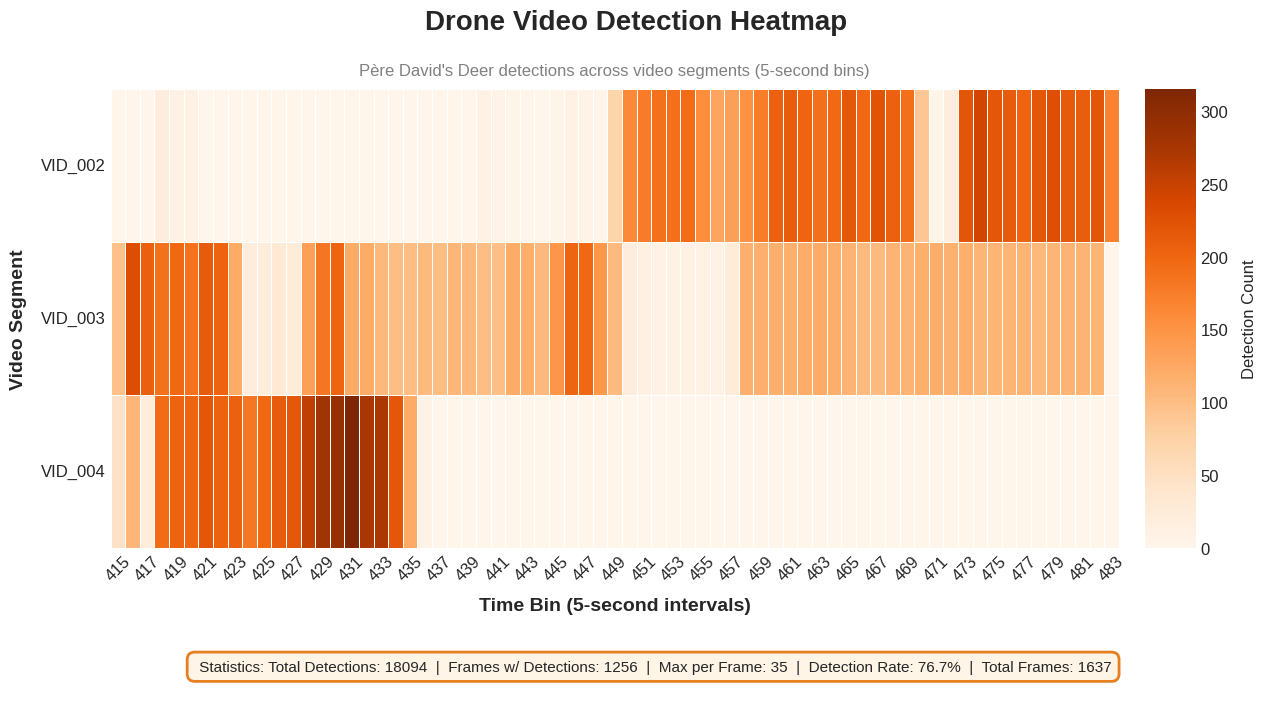


 Saved: drone_detection_heatmap.png


In [ ]:
# Aggregate drone data by video and time bin
drone_agg = drone_processed.groupby(['video_id', 'time_bin'])['num_animals'].sum().reset_index()

# Pivot for heatmap
drone_pivot = drone_agg.pivot(index='video_id', columns='time_bin', values='num_animals').fillna(0)

# Calculate statistics
total_detections = drone_processed['num_animals'].sum()
frames_with_detections = (drone_processed['num_animals'] > 0).sum()
max_in_frame = drone_processed['num_animals'].max()
detection_rate = (frames_with_detections / len(drone_processed)) * 100

drone_stats = {
    'Total Detections': int(total_detections),
    'Frames w/ Detections': int(frames_with_detections),
    'Max per Frame': int(max_in_frame),
    'Detection Rate': f'{detection_rate:.1f}%',
    'Total Frames': len(drone_processed)
}

# Create heatmap
fig_drone = create_detection_heatmap(
    data=drone_pivot,
    title="Drone Video Detection Heatmap",
    subtitle="Père David's Deer detections across video segments (5-second bins)",
    x_label="Time Bin (5-second intervals)",
    y_label="Video Segment",
    cmap='Oranges',
    stats_dict=drone_stats,
    annot=False,  # Too many cells
    stats_color='#e67e22',
    stats_bg='#fef5e7'
)

plt.savefig('drone_detection_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("\n Saved: drone_detection_heatmap.png")

## 5. Bioacoustic Detection Heatmap

Visualizes bird species detected from audio recordings.

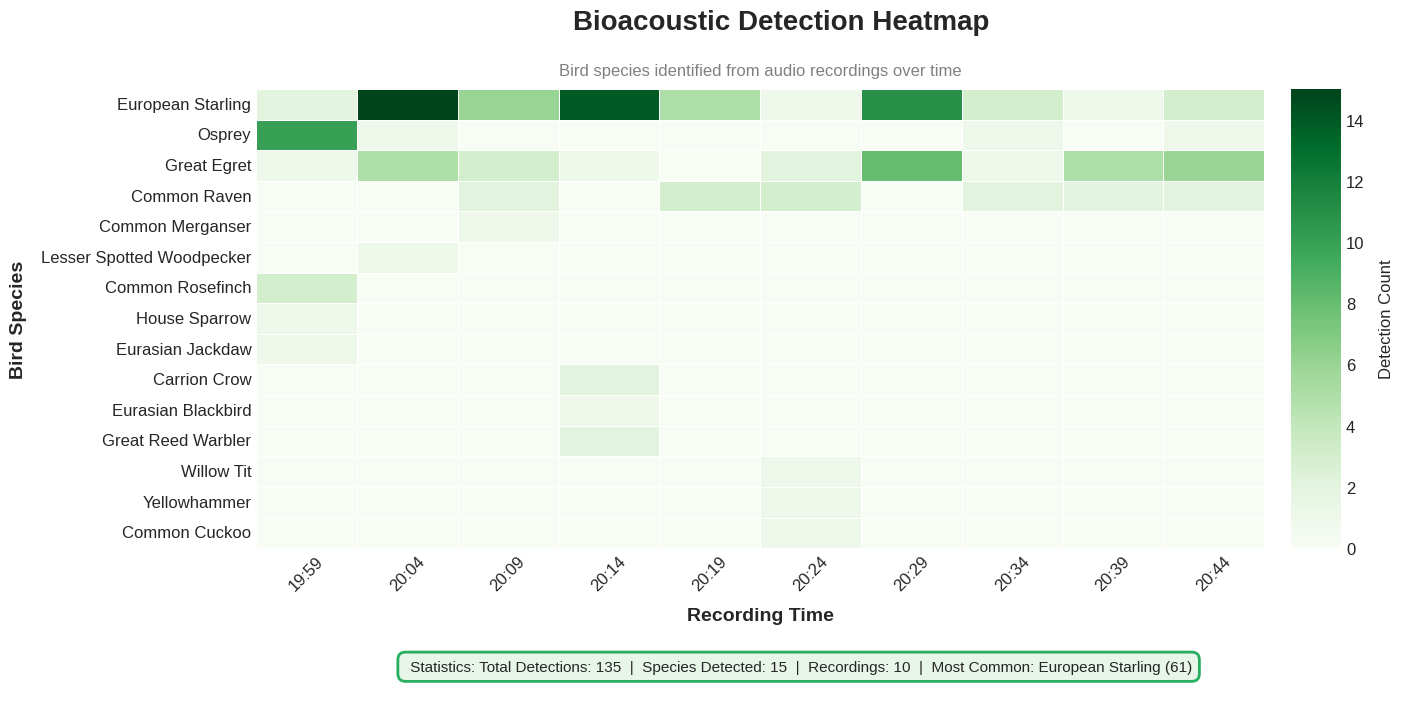


✅ Saved: bioacoustic_detection_heatmap.png


In [ ]:
# Filter for recording data only (bioacoustic)
bioacoustic_df = bird_processed[bird_processed['recording/photo/frame'] == 'recording'].copy()

if len(bioacoustic_df) > 0:
    # Get species columns
    species_cols = [col for col in bioacoustic_df.columns if 'Count' in col]

    # Create observation index (sequential recordings)
    bioacoustic_df['obs_idx'] = range(1, len(bioacoustic_df) + 1)

    # Prepare data for species x observation heatmap
    species_data = bioacoustic_df[['obs_idx'] + species_cols].set_index('obs_idx')
    species_data.columns = [col.replace(' Count', '') for col in species_data.columns]

    # Filter to species with at least 1 detection
    active_species = species_data.columns[species_data.sum() > 0]
    species_data = species_data[active_species].T

    # Calculate statistics
    total_birds = bioacoustic_df['total_birds'].sum()
    unique_species = len(active_species)
    most_common = species_data.sum(axis=1).idxmax()
    most_common_count = int(species_data.sum(axis=1).max())

    bioacoustic_stats = {
        'Total Detections': int(total_birds),
        'Species Detected': unique_species,
        'Recordings': len(bioacoustic_df),
        'Most Common': f'{most_common} ({most_common_count})'
    }

    # Create time labels from datetime
    time_labels = bioacoustic_df['datetime'].dt.strftime('%H:%M').tolist()

    # Rename columns to time labels
    species_data.columns = time_labels

    # Create heatmap
    fig_bio = create_detection_heatmap(
        data=species_data,
        title="Bioacoustic Detection Heatmap",
        subtitle="Bird species identified from audio recordings over time",
        x_label="Recording Time",
        y_label="Bird Species",
        cmap='Greens',
        stats_dict=bioacoustic_stats,
        annot=True,
        stats_color='#27ae60',
        stats_bg='#e8f5e9'
    )

    plt.savefig('bioacoustic_detection_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print("\n✅ Saved: bioacoustic_detection_heatmap.png")
else:
    print("⚠️ No bioacoustic (recording) data found in the dataset.")

## 6. Camera Trap Photo Detection Heatmap

Visualizes wildlife detected in camera trap photographs across different locations.

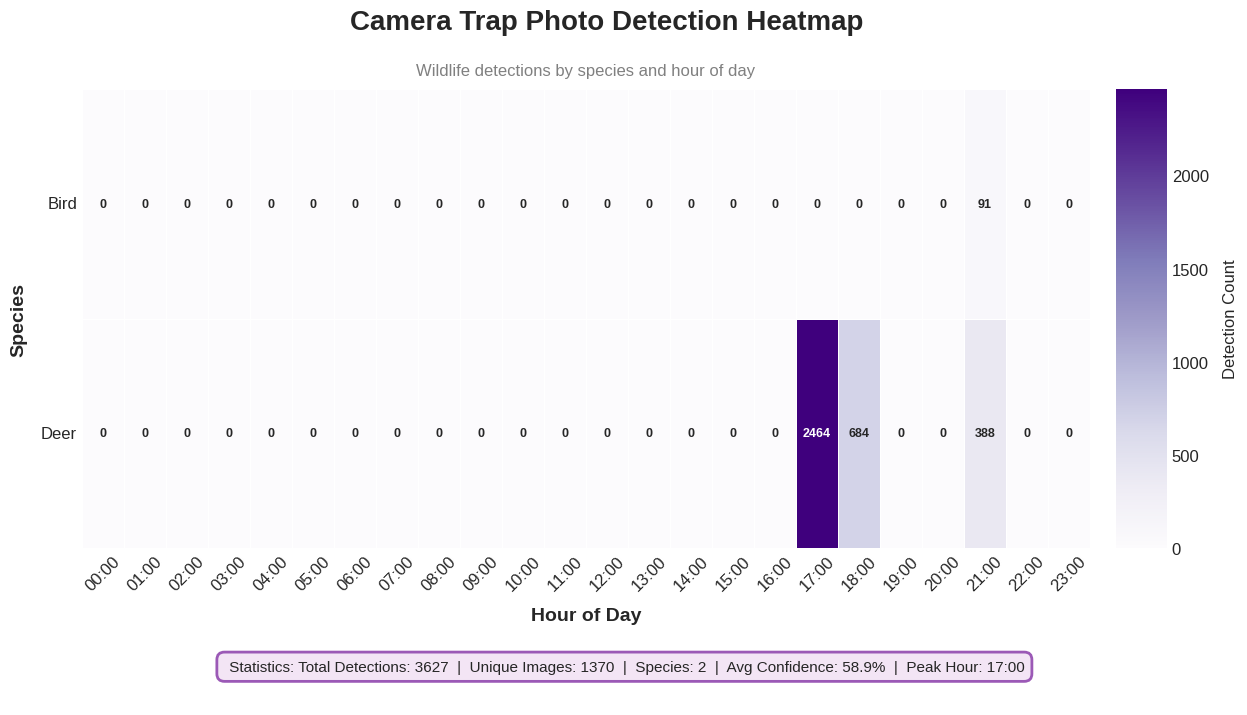


Saved: photo_detection_heatmap.png


In [ ]:
# Create heatmap: Species x Hour of Day
# Count detections per species per hour
photo_species_hour = photo_processed.groupby(['species_group', 'hour_bin']).size().reset_index(name='count')

# Pivot for heatmap
photo_pivot_hour = photo_species_hour.pivot(
    index='species_group',
    columns='hour_bin',
    values='count'
).fillna(0)

# Ensure all hours are present (0-23)
all_hours = list(range(24))
for h in all_hours:
    if h not in photo_pivot_hour.columns:
        photo_pivot_hour[h] = 0
photo_pivot_hour = photo_pivot_hour[sorted(photo_pivot_hour.columns)]

# Create hour labels
hour_labels = [f'{h:02d}:00' for h in photo_pivot_hour.columns]
photo_pivot_hour.columns = hour_labels

# Capitalize species names
photo_pivot_hour.index = photo_pivot_hour.index.str.title()

# Calculate statistics
total_photo_detections = len(photo_processed)
unique_images = photo_processed['image'].nunique()
unique_species_photo = photo_processed['species_group'].nunique()
avg_confidence = photo_processed['bioclip_score'].mean()
peak_hour = photo_processed['hour_bin'].mode().iloc[0]

photo_stats = {
    'Total Detections': total_photo_detections,
    'Unique Images': unique_images,
    'Species': unique_species_photo,
    'Avg Confidence': f'{avg_confidence:.1%}',
    'Peak Hour': f'{peak_hour:02d}:00'
}

# Create heatmap
fig_photo = create_detection_heatmap(
    data=photo_pivot_hour,
    title="Camera Trap Photo Detection Heatmap",
    subtitle="Wildlife detections by species and hour of day",
    x_label="Hour of Day",
    y_label="Species",
    cmap='Purples',
    stats_dict=photo_stats,
    annot=True,
    fmt='.0f',
    stats_color='#9b59b6',
    stats_bg='#f3e5f5'
)

plt.savefig('photo_detection_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("\nSaved: photo_detection_heatmap.png")

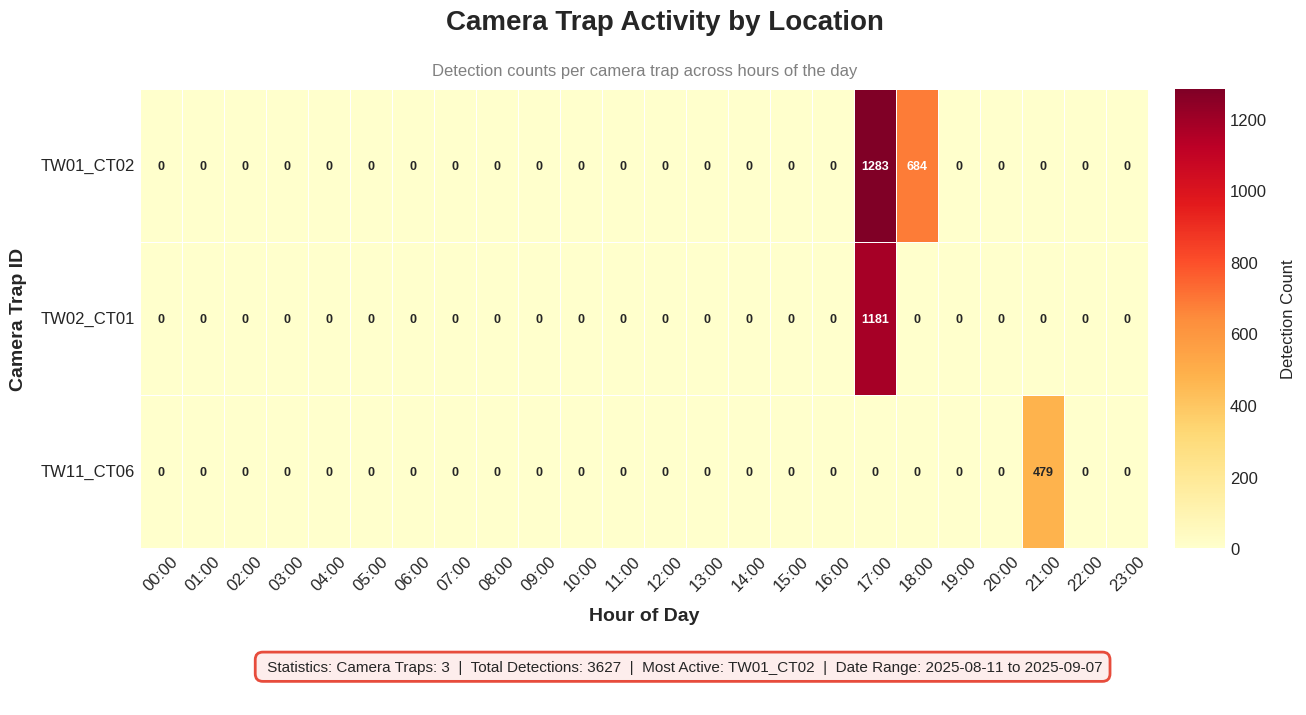


 Saved: camera_location_heatmap.png


In [ ]:
# Create additional heatmap: Camera Trap Location x Hour
photo_camera_hour = photo_processed.groupby(['camera_id', 'hour_bin']).size().reset_index(name='count')

# Pivot for heatmap
photo_pivot_camera = photo_camera_hour.pivot(
    index='camera_id',
    columns='hour_bin',
    values='count'
).fillna(0)

# Ensure all hours are present
for h in range(24):
    if h not in photo_pivot_camera.columns:
        photo_pivot_camera[h] = 0
photo_pivot_camera = photo_pivot_camera[sorted(photo_pivot_camera.columns)]

# Create hour labels
hour_labels = [f'{h:02d}:00' for h in photo_pivot_camera.columns]
photo_pivot_camera.columns = hour_labels

# Calculate camera-specific stats
camera_stats = {
    'Camera Traps': photo_processed['camera_id'].nunique(),
    'Total Detections': len(photo_processed),
    'Most Active': photo_processed['camera_id'].value_counts().idxmax(),
    'Date Range': f"{photo_processed['date'].min()} to {photo_processed['date'].max()}"
}

# Create heatmap
fig_camera = create_detection_heatmap(
    data=photo_pivot_camera,
    title="Camera Trap Activity by Location",
    subtitle="Detection counts per camera trap across hours of the day",
    x_label="Hour of Day",
    y_label="Camera Trap ID",
    cmap='YlOrRd',
    stats_dict=camera_stats,
    annot=True,
    fmt='.0f',
    stats_color='#e74c3c',
    stats_bg='#fdedec'
)

plt.savefig('camera_location_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("\n Saved: camera_location_heatmap.png")

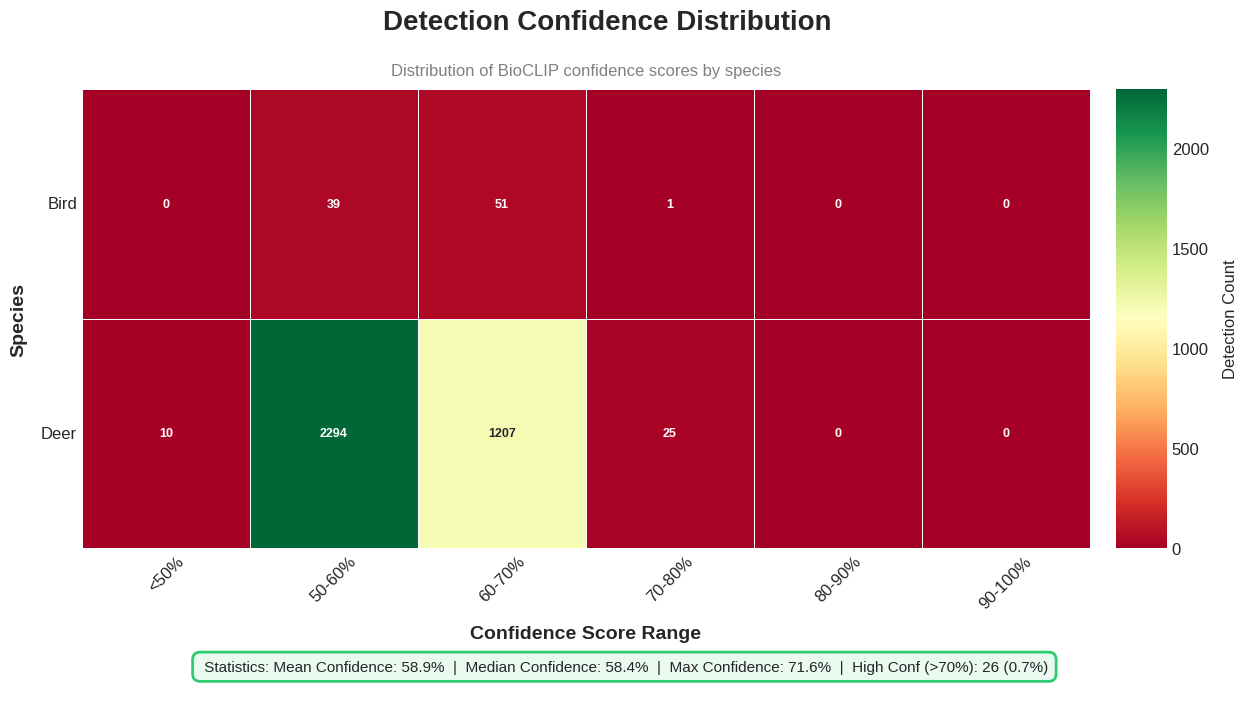


 Saved: confidence_distribution_heatmap.png


In [ ]:
# Create heatmap: Confidence Score Distribution by Species
# Bin confidence scores
photo_processed['conf_bin'] = pd.cut(
    photo_processed['bioclip_score'],
    bins=[0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    labels=['<50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%']
)

# Count by species and confidence bin
conf_species = photo_processed.groupby(['species_group', 'conf_bin']).size().reset_index(name='count')

# Pivot
conf_pivot = conf_species.pivot(
    index='species_group',
    columns='conf_bin',
    values='count'
).fillna(0)

# Capitalize species names
conf_pivot.index = conf_pivot.index.str.title()

# Stats
conf_stats = {
    'Mean Confidence': f"{photo_processed['bioclip_score'].mean():.1%}",
    'Median Confidence': f"{photo_processed['bioclip_score'].median():.1%}",
    'Max Confidence': f"{photo_processed['bioclip_score'].max():.1%}",
    'High Conf (>70%)': f"{(photo_processed['bioclip_score'] > 0.7).sum()} ({(photo_processed['bioclip_score'] > 0.7).mean():.1%})"
}

# Create heatmap
fig_conf = create_detection_heatmap(
    data=conf_pivot,
    title="Detection Confidence Distribution",
    subtitle="Distribution of BioCLIP confidence scores by species",
    x_label="Confidence Score Range",
    y_label="Species",
    cmap='RdYlGn',
    stats_dict=conf_stats,
    annot=True,
    fmt='.0f',
    stats_color='#2ecc71',
    stats_bg='#eafaf1'
)

plt.savefig('confidence_distribution_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("\n Saved: confidence_distribution_heatmap.png")

## 7. Combined Multi-Modality Summary Dashboard

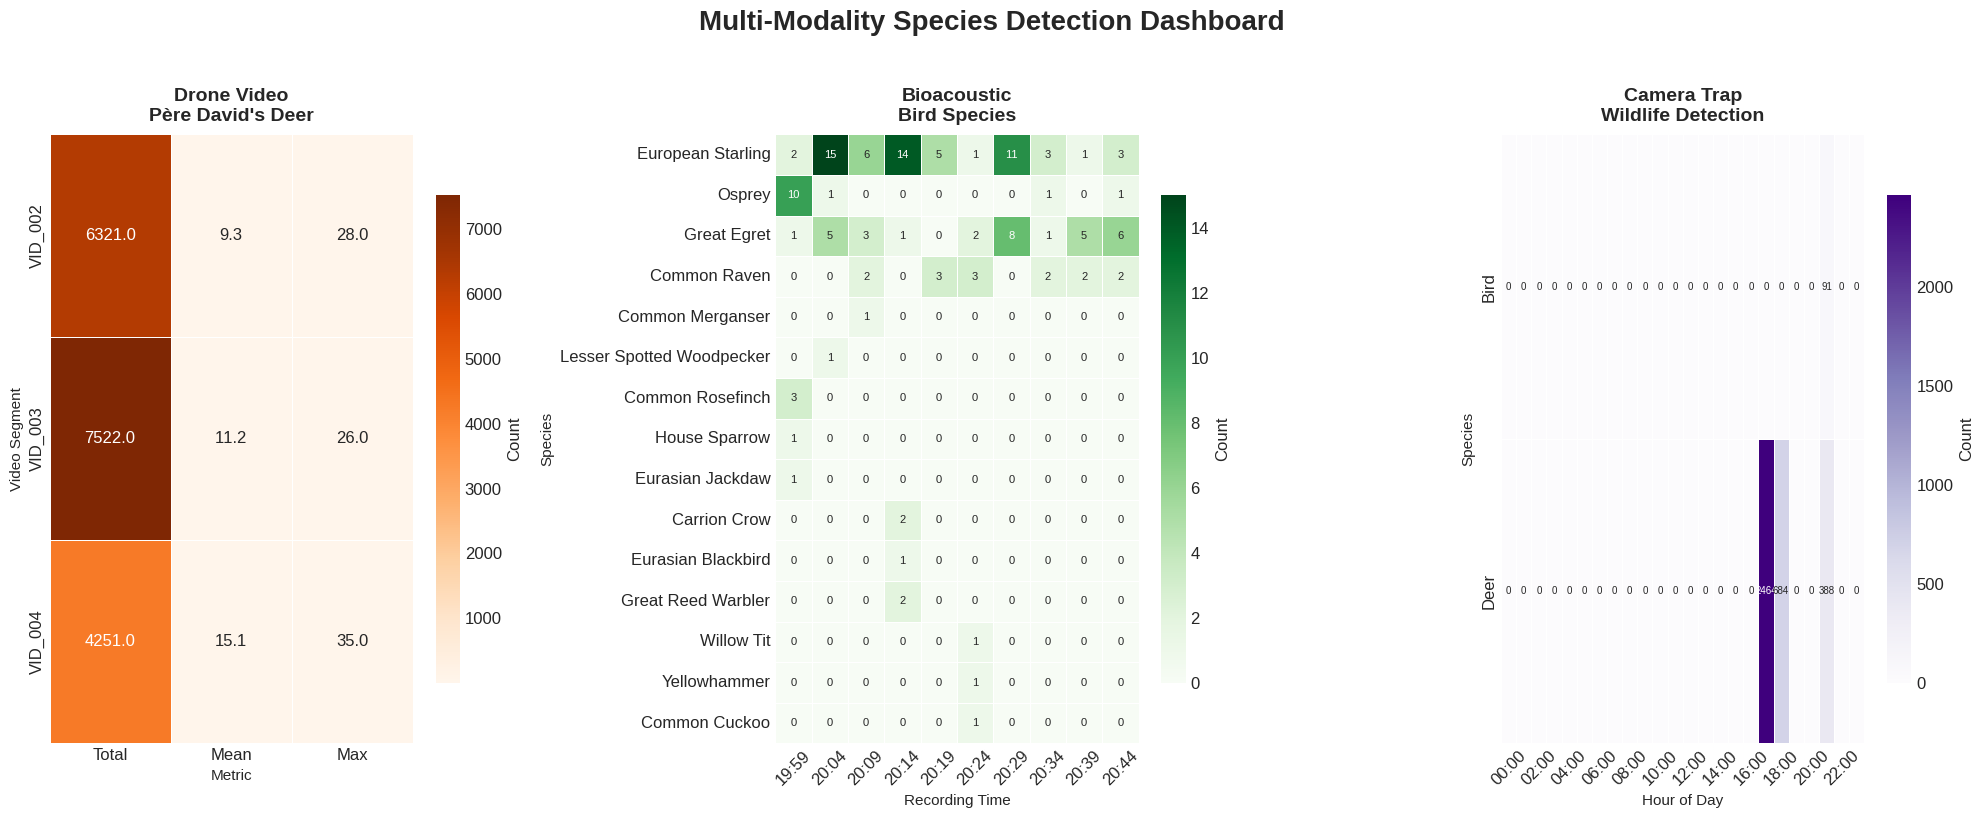


 Saved: multimodality_dashboard.png


In [ ]:
# Create a combined dashboard with all three modalities
fig, axes = plt.subplots(1, 3, figsize=(20, 8), facecolor='white')

# Drone heatmap (simplified view)
ax1 = axes[0]
# Aggregate by video only for simpler view
drone_simple = drone_processed.groupby('video_id')['num_animals'].agg(['sum', 'mean', 'max']).reset_index()
drone_simple_pivot = drone_simple.set_index('video_id')[['sum', 'mean', 'max']]
drone_simple_pivot.columns = ['Total', 'Mean', 'Max']
sns.heatmap(
    drone_simple_pivot,
    ax=ax1,
    cmap='Oranges',
    linewidths=0.5,
    cbar_kws={'label': 'Count', 'shrink': 0.8},
    annot=True,
    fmt='.1f'
)
ax1.set_title('Drone Video\nPère David\'s Deer', fontsize=14, fontweight='bold', pad=10)
ax1.set_xlabel('Metric', fontsize=11)
ax1.set_ylabel('Video Segment', fontsize=11)

# Bioacoustic heatmap
ax2 = axes[1]
if 'species_data' in dir() and len(species_data) > 0:
    sns.heatmap(
        species_data,
        ax=ax2,
        cmap='Greens',
        linewidths=0.5,
        cbar_kws={'label': 'Count', 'shrink': 0.8},
        annot=True,
        fmt='g',
        annot_kws={'size': 8}
    )
ax2.set_title('Bioacoustic\nBird Species', fontsize=14, fontweight='bold', pad=10)
ax2.set_xlabel('Recording Time', fontsize=11)
ax2.set_ylabel('Species', fontsize=11)
ax2.tick_params(axis='x', rotation=45)

# Photo heatmap
ax3 = axes[2]
sns.heatmap(
    photo_pivot_hour,
    ax=ax3,
    cmap='Purples',
    linewidths=0.5,
    cbar_kws={'label': 'Count', 'shrink': 0.8},
    annot=True,
    fmt='.0f',
    annot_kws={'size': 7}
)
ax3.set_title('Camera Trap\nWildlife Detection', fontsize=14, fontweight='bold', pad=10)
ax3.set_xlabel('Hour of Day', fontsize=11)
ax3.set_ylabel('Species', fontsize=11)
ax3.tick_params(axis='x', rotation=45)

# Main title
fig.suptitle('Multi-Modality Species Detection Dashboard',
             fontsize=20, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('multimodality_dashboard.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("\n Saved: multimodality_dashboard.png")